In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Graph-local RZZZ IQP policy: matched-uniform comparison

This notebook tests whether adding a deliberately structured three-local IQP
sector learns CartPole-v1/200 faster than the ten-qubit, one-layer cubic-graph
majority baseline. The comparison uses twenty matched seeds. The primary
endpoint is normalized training-return AUC over 500 episodes; the secondary
endpoint is the first strict rolling-100 return crossing of 195.

Both conditions use the same connected 3-regular graph, four-feature neural
embedding on all ten wires, local (R_Z) and graph-edge (R_{ZZ}) rotations,
terminal Hadamards, and deterministic majority on the nine measured wires
(q_1,\ldots,q_9). Wire (q_{10}) remains coupled but unmeasured. The candidate
adds ten graph-local (R_{ZZZ}) generators.

## Locked matched design

The candidate has one graph-local R_{ZZZ} generator per graph vertex. Every
triple is a length-two path in the fixed cubic graph; together the ten triples
cover every graph edge, and every qubit appears in exactly three triples. The
65 shared trainable values are bitwise identical for each matched seed. The ten
added angles are independently sampled from U[0,2pi), exactly the same QASP
uniform distribution as the other rotation angles, and every parameter uses the same Adam
learning rate 0.03. This directly tests the added generator sector rather than
a zero-initialized residual or a task-informed initialization.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import copy, hashlib, inspect, json, math, platform, shutil, subprocess, sys, time
from itertools import combinations
from pathlib import Path

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from scipy import sparse

import qasp
from qasp.circuits.constructor import CircuitBuilder
from qasp.circuits.templates import IQPAnsatz
from qasp.feature_maps.templates import NeuralEmbedding
from qasp.rl.model import create_model
from qasp.rl.torchrl import REINFORCE

torch.set_num_threads(1)

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "tests" / "results" / "cartpole_10q_graph_local_rzzz_uniform_ablation"
RUNS_DIR = RESULTS_DIR / "runs"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, RUNS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BASELINE_DIR = ROOT / "tests" / "results" / "majority_local_sector_ablation"
BASELINE_CONFIG_PATH = BASELINE_DIR / "experiment_config.json"
BASELINE_TRAIN_PATH = BASELINE_DIR / "training_episode_returns.csv"
BASELINE_EVAL_PATH = BASELINE_DIR / "heldout_evaluation_returns.csv"
BASELINE_METADATA_PATH = BASELINE_DIR / "run_metadata.csv"
BASELINE_AUDIT_PATH = BASELINE_DIR / "matched_initialization_audit.csv"
SOURCE_BASELINE_RUNS = (ROOT / "tests" / "results" /
                        "cartpole_10q_graph_local_rzzz_fast_convergence" / "runs")

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
    "lines.linewidth": 1.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()
    except Exception:
        return "unavailable"

CURRENT_BRANCH = git_output("branch", "--show-current")
CURRENT_COMMIT = git_output("rev-parse", "HEAD")
print("QASP root:", ROOT)
print("Current branch (recorded, never changed here):", CURRENT_BRANCH)
print("Current commit:", CURRENT_COMMIT)
print("Results:", RESULTS_DIR)
print("PennyLane", qml.__version__, "| PyTorch", torch.__version__, "| Gymnasium", gym.__version__)

QASP root: .
Current branch (recorded, never changed here): codex/circuit-cutting
Current commit: 8c9ccace59bfacfe4bc2df7155346aebe4506a2a
Results: ./tests/results/cartpole_10q_graph_local_rzzz_uniform_ablation
PennyLane 0.42.2 | PyTorch 2.7.0 | Gymnasium 1.0.0


## Locked matched protocol

The graph-local triples and full-period uniform initializer below are fixed
before running the candidate. The already completed baseline trajectories are
reused only after exact architecture, seed, and initialization-hash checks.

In [2]:
SEEDS = (61, 67, 71, 73, 79, 83, 89, 97, 101, 103,
         107, 109, 113, 127, 131, 137, 139, 149, 151, 157)
N_QUBITS = 10
N_LAYERS = 1
MEASUREMENT_WIRES = tuple(range(9))
N_EPISODES = 500
N_EVAL_EPISODES = 100
MAX_STEPS = 200
FINAL_WINDOW = 50
MOVING_WINDOW = 20
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100
N_JOBS = 4

RUN_PRODUCTION = True

BASE_LR = 0.03
RZZZ_LR = BASE_LR
EXTRA_PARAMETER_MASTER_SEED = 20261024

TRAINING = {
    "gamma": 0.99, "lr": 0.03, "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)", "batch_episodes": 5,
    "normalize_mode": "clip", "normalize_returns": True,
    "baseline_type": "ema", "baseline_momentum": 0.05,
    "entropy_coef": 0.005, "max_grad_norm": 1.0,
}

EXPANDER_EDGES = (
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
)
EXPECTED_GRAPH_SEED = 1039606416
EXPECTED_GRAPH_GAP = 0.853351

SELECTED_TRIPLES = (
    (0, 5, 6), (1, 4, 7), (1, 2, 6), (3, 4, 7), (3, 4, 9),
    (0, 5, 8), (2, 5, 6), (0, 1, 7), (2, 8, 9), (3, 8, 9),
)
assert len(set(SELECTED_TRIPLES)) == 10

graph = nx.Graph()
graph.add_nodes_from(range(N_QUBITS)); graph.add_edges_from(EXPANDER_EDGES)
eigenvalues = np.linalg.eigvalsh(nx.to_numpy_array(graph, nodelist=range(N_QUBITS)))
graph_gap = float(eigenvalues[-1] - eigenvalues[-2])
assert nx.is_connected(graph) and all(degree == 3 for _, degree in graph.degree())
assert abs(graph_gap - EXPECTED_GRAPH_GAP) < 5e-7

print("Graph edges:", EXPANDER_EDGES)
print("Graph gap:", f"{graph_gap:.6f}", "| accepted seed:", EXPECTED_GRAPH_SEED)
print("Measured wires:", MEASUREMENT_WIRES, "| coupled/unmeasured wire: 9")
print("Selected RZZZ triples:", SELECTED_TRIPLES)
node_counts = {wire: sum(wire in triple for triple in SELECTED_TRIPLES)
               for wire in range(N_QUBITS)}
covered_edges = {tuple(sorted((u, v))) for triple in SELECTED_TRIPLES
                 for u, v in combinations(triple, 2)
                 if graph.has_edge(u, v)}
assert set(node_counts.values()) == {3}
assert covered_edges == {tuple(sorted(edge)) for edge in EXPANDER_EDGES}
assert all(any(center in triple and len(set(triple) & set(graph.neighbors(center))) == 2
               for center in triple) for triple in SELECTED_TRIPLES)
print("Per-qubit triple count:", node_counts, "| covered graph edges:", len(covered_edges))
print("Production enabled:", RUN_PRODUCTION)

Graph edges: ((0, 5), (0, 6), (0, 7), (1, 2), (1, 4), (1, 7), (2, 6), (2, 8), (3, 4), (3, 7), (3, 9), (4, 9), (5, 6), (5, 8), (8, 9))
Graph gap: 0.853351 | accepted seed: 1039606416
Measured wires: (0, 1, 2, 3, 4, 5, 6, 7, 8) | coupled/unmeasured wire: 9
Selected RZZZ triples: ((0, 5, 6), (1, 4, 7), (1, 2, 6), (3, 4, 7), (3, 4, 9), (0, 5, 8), (2, 5, 6), (0, 1, 7), (2, 8, 9), (3, 8, 9))
Per-qubit triple count: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3, 8: 3, 9: 3} | covered graph edges: 15
Production enabled: True


## Baseline protocol provenance

The earlier controlled experiment supplies the locked architecture and trainer
settings. Baseline trajectories come from the completed twenty-seed residual
study; candidate trajectories are newly generated on the same seeds.

In [3]:
baseline_config = json.loads(BASELINE_CONFIG_PATH.read_text())
spec = baseline_config["architectures"]["expander_10_L1"]
assert baseline_config["training_episodes"] == N_EPISODES
assert baseline_config["heldout_evaluation_episodes_per_seed"] == N_EVAL_EPISODES
assert baseline_config["trainer_side_step_cap"] == MAX_STEPS
assert baseline_config["training"] == TRAINING
assert spec["n_qubits"] == N_QUBITS and spec["n_layers"] == N_LAYERS
assert tuple(map(tuple, spec["edges"])) == EXPANDER_EDGES
assert tuple(spec["measurement_wires"]) == MEASUREMENT_WIRES
assert spec["initializer"] == "uniform"
assert spec["expected_quantum_parameters"] == 65
assert spec["accepted_networkx_seed"] == EXPECTED_GRAPH_SEED
print("Locked protocol verified from", BASELINE_CONFIG_PATH)
print("Fresh evaluation seeds:", SEEDS)

Locked protocol verified from ./tests/results/majority_local_sector_ablation/experiment_config.json
Fresh evaluation seeds: (61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157)


## Exact QASP circuit and validated statevector implementation

`CubicRZZZAnsatz` is a QASP `CircuitBuilder`-compatible one-layer program:

\[
H^{\otimes 10}\;D_Z(\mathbf{s};W,\alpha,\beta,\gamma)\;H^{\otimes 10},
\]

where (D_Z) contains the neural (R_Z) encoding, ten trainable local
(R_Z) gates, the fixed graph's fifteen (R_{ZZ}) gates, and the ten selected
(R_{ZZZ}) gates. The native QASP sparse majority projector is retained as
the reference. The faster differentiable statevector implementation is used
for production only after probability and analytic-gradient agreement.

In [4]:
def majority_pi0_diagonal(n_qubits=N_QUBITS, measured=MEASUREMENT_WIRES):
    states = np.arange(1 << n_qubits, dtype=np.int64)
    shifts = np.asarray([n_qubits - 1 - wire for wire in measured])
    bits = ((states[:, None] >> shifts[None, :]) & 1)
    # Nine measured bits: action 0 iff zeros are the strict majority.
    return (bits.sum(axis=1) <= len(measured) // 2).astype(np.float64)


class CubicRZZZAnsatz:
    def __init__(self, triples):
        self.n_qubits = N_QUBITS
        self.n_layers = 1
        self.feature_map = NeuralEmbedding(
            n_qubits=N_QUBITS, features=4, rotations="Z"
        )
        self.reuploading = True
        self.include_single_qubit = True
        self.edges = list(EXPANDER_EDGES)
        self.triples = [tuple(map(int, triple)) for triple in triples]
        self.z_gates = None; self.parity_gates = None; self.CNOT_Gates = None

    def get_param_shapes(self):
        return [(N_QUBITS * 4,), (N_QUBITS + len(self.edges) + len(self.triples),)]

    def __call__(self, inputs=None, input_scaling_params=None, params=None):
        for wire in range(N_QUBITS):
            qml.Hadamard(wires=wire)
        self.feature_map(inputs, input_scaling_params=input_scaling_params)
        for wire in range(N_QUBITS):
            qml.RZ(params[wire], wires=wire)
        offset = N_QUBITS
        for index, edge in enumerate(self.edges):
            qml.PauliRot(params[offset + index], "ZZ", wires=list(edge))
        offset += len(self.edges)
        for index, triple in enumerate(self.triples):
            qml.PauliRot(params[offset + index], "ZZZ", wires=list(triple))
        for wire in range(N_QUBITS):
            qml.Hadamard(wires=wire)


def qasp_initial_state(seed):
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": 1, "imprimitive_pattern": list(EXPANDER_EDGES),
            "reuploading": True, "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2, "init": "uniform",
        "device": "lightning.qubit", "diff_method": "adjoint", "shots": None,
        "softmax_activation": False, "output_scaling": None, "torchrl": False,
        "measurement_qubits": list(MEASUREMENT_WIRES),
        "parity_cnot_decomposition": False, "policy": "parity-like",
        "training_method": "expectation", "enable_mpi": False,
    }
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    model = create_model("PQCBorn", config, n_qubits=N_QUBITS)
    state = {key: value.detach().cpu().clone()
             for key, value in model.qlayer.state_dict().items()}
    del model
    return state


def tensor_hash(*tensors):
    return hashlib.sha256(b"".join(
        tensor.detach().cpu().contiguous().numpy().tobytes() for tensor in tensors
    )).hexdigest()


def extra_parameter_seed(seed):
    sequence = np.random.SeedSequence([EXTRA_PARAMETER_MASTER_SEED, int(seed)])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def extra_initial_angles(seed, count):
    generator = torch.Generator(device="cpu")
    generator.manual_seed(extra_parameter_seed(seed))
    return torch.empty(count, dtype=torch.float32).uniform_(
        0.0, 2 * math.pi, generator=generator
    )


class NativeQASPMajority(torch.nn.Module):
    def __init__(self, triples, seed):
        super().__init__()
        ansatz = CubicRZZZAnsatz(triples)
        builder = CircuitBuilder(n_qubits=N_QUBITS)
        builder.set_ansatz(ansatz)
        matrix = sparse.diags(
            majority_pi0_diagonal(), format="csr", dtype=np.float64
        )
        observable = qml.SparseHamiltonian(matrix, wires=range(N_QUBITS))
        builder.set_measurement("expectation", wires=range(N_QUBITS),
                                observables=[observable])
        builder.build()
        builder.compile(device="lightning.qubit", diff_method="adjoint",
                        shots=None, device_vjp=False, batch_obs=False)
        torch.manual_seed(int(seed)); np.random.seed(int(seed))
        self.qlayer = builder.create_torchlayer(initialization="uniform")
        self.builder = builder
        self.triples = tuple(triples)

    def forward(self, x):
        p0 = self.qlayer(x)
        if p0.ndim and p0.shape[-1] == 1:
            p0 = p0.squeeze(-1)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )


class ExactTorchCubicMajority(torch.nn.Module):
    def __init__(self, triples, seed, uniform_extension=False):
        super().__init__()
        initial = qasp_initial_state(seed)
        self.input_scaling_params = torch.nn.Parameter(
            initial["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial["params"].clone())
        self.rzzz_params = torch.nn.Parameter(
            extra_initial_angles(seed, len(triples)) if uniform_extension
            else torch.zeros(len(triples), dtype=torch.float32)
        )
        self.triples = tuple(tuple(map(int, t)) for t in triples)
        self.forward_calls = 0

        dimension = 1 << N_QUBITS
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(N_QUBITS - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        z_signs = (1.0 - 2.0 * bits).T
        self.register_buffer("z_signs", z_signs)
        self.register_buffer("zz_signs", torch.stack([
            z_signs[left] * z_signs[right] for left, right in EXPANDER_EDGES
        ]))
        if self.triples:
            rzzz_signs = torch.stack([
                z_signs[a] * z_signs[b] * z_signs[c]
                for a, b, c in self.triples
            ])
        else:
            rzzz_signs = torch.empty((0, dimension), dtype=torch.float32)
        self.register_buffer("rzzz_signs", rzzz_signs)
        measured_index = torch.zeros(dimension, dtype=torch.long)
        for wire in MEASUREMENT_WIRES:
            measured_index = (measured_index << 1) | bits[:, wire].to(torch.long)
        self.register_buffer("measured_index", measured_index)
        measured_states = np.arange(1 << len(MEASUREMENT_WIRES), dtype=np.int64)
        measured_weights = np.asarray([
            int(value).bit_count() for value in measured_states
        ])
        self.register_buffer("pi0_basis", torch.as_tensor(
            measured_weights <= len(MEASUREMENT_WIRES) // 2,
            dtype=torch.float32,
        ))

    @staticmethod
    def _hadamards(state):
        result = state; width = 1; dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left, right = blocks[..., 0, :], blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states):
        states = torch.as_tensor(states, dtype=torch.float32)
        dimension = 1 << N_QUBITS
        batch_shape = states.shape[:-1]
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)
        weights = self.input_scaling_params.reshape(N_QUBITS, 4)
        encoded = torch.einsum("...f,qf->...q", states, weights)
        angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
        angle = angle + torch.einsum("q,qd->d", self.params[:N_QUBITS], self.z_signs)
        angle = angle + torch.einsum("e,ed->d", self.params[N_QUBITS:], self.zz_signs)
        if len(self.triples):
            angle = angle + torch.einsum("t,td->d", self.rzzz_params, self.rzzz_signs)
        state = state * torch.exp(-0.5j * angle)
        state = self._hadamards(state)
        full = state.abs().square().real
        measured_dimension = 1 << len(MEASUREMENT_WIRES)
        flat = full.reshape(-1, dimension)
        measured = full.new_zeros((flat.shape[0], measured_dimension))
        measured.scatter_add_(
            1, self.measured_index[None, :].expand(flat.shape[0], -1), flat
        )
        return measured.reshape(*batch_shape, measured_dimension)

    def forward(self, x):
        self.forward_calls += 1
        basis = self.exact_basis_probs(x)
        p0 = torch.einsum("...d,d->...", basis, self.pi0_basis)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )

## Preflight validation of the matched-uniform circuit

These tests do not train. They verify:

- all 65 shared tensors are bitwise identical between baseline and candidate;
- each added R_{ZZZ} angle is a reproducible U[0,2pi) draw;
- the added-angle gradient is nonzero, so the three-local sector can learn;
- QASP and the accelerated implementation agree in probabilities and gradients;
- the native tape contains precisely the intended (R_Z), (R_{ZZ}), and ten
  (R_{ZZZ}) gates and the nine-bit majority projector.

In [5]:
initial_hash_rows = []
for seed in SEEDS:
    baseline = ExactTorchCubicMajority((), seed)
    candidate = ExactTorchCubicMajority(
        SELECTED_TRIPLES, seed, uniform_extension=True
    )
    assert torch.equal(baseline.input_scaling_params, candidate.input_scaling_params)
    assert torch.equal(baseline.params, candidate.params)
    assert torch.equal(candidate.rzzz_params,
                       extra_initial_angles(seed, len(SELECTED_TRIPLES)))
    assert torch.all(candidate.rzzz_params >= 0.0)
    assert torch.all(candidate.rzzz_params < 2 * math.pi)
    source_meta = json.loads((SOURCE_BASELINE_RUNS /
        f"expander_10_L1__baseline__seed_{seed}.json").read_text())
    assert tensor_hash(baseline.input_scaling_params, baseline.params) == \
        source_meta["initial_shared_parameter_sha256"]
    initial_hash_rows.append({
        "seed": seed,
        "baseline_shared_hash": tensor_hash(baseline.input_scaling_params, baseline.params),
        "candidate_shared_hash": tensor_hash(candidate.input_scaling_params, candidate.params),
        "rzzz_uniform_hash": tensor_hash(candidate.rzzz_params),
    })
print("All 20 seeds have bitwise-identical shared tensors and reproducible uniform RZZZ angles.")

validation_state = torch.tensor([0.2, -0.1, 0.05, 0.3], dtype=torch.float32)
seed = SEEDS[0]
initial = qasp_initial_state(seed)
fast = ExactTorchCubicMajority(SELECTED_TRIPLES, seed, uniform_extension=True)
assert sum(p.numel() for p in fast.parameters()) == 75

(-torch.log(fast(validation_state)[0])).backward()
assert float(fast.rzzz_params.grad.norm()) > 1e-8

native = NativeQASPMajority(SELECTED_TRIPLES, seed)
combined = torch.cat((fast.params.detach(), fast.rzzz_params.detach()))
native.qlayer.load_state_dict({
    "input_scaling_params": fast.input_scaling_params.detach().clone(),
    "params": combined.clone(),
})
fast.zero_grad(set_to_none=True)
expected = native(validation_state); actual = fast(validation_state)
torch.testing.assert_close(actual, expected, atol=3e-6, rtol=3e-6)
(-torch.log(expected[0])).backward(); (-torch.log(actual[0])).backward()
native_grad = torch.cat((native.qlayer.input_scaling_params.grad.reshape(-1),
                         native.qlayer.params.grad.reshape(-1)))
fast_grad = torch.cat((fast.input_scaling_params.grad.reshape(-1),
                       fast.params.grad.reshape(-1), fast.rzzz_params.grad.reshape(-1)))
torch.testing.assert_close(fast_grad, native_grad, atol=4e-5, rtol=5e-4)

tape = qml.tape.make_qscript(native.builder.circuit)(
    inputs=validation_state,
    input_scaling_params=native.qlayer.input_scaling_params,
    params=native.qlayer.params,
)
words = [op.hyperparameters.get("pauli_word") for op in tape.operations
         if op.name == "PauliRot"]
audit = {
    "trainable_parameter_count": sum(p.numel() for p in fast.parameters()),
    "n_hadamards": sum(op.name == "Hadamard" for op in tape.operations),
    "n_embedding_RZ": words.count("Z"),
    "n_local_RZ": sum(op.name == "RZ" for op in tape.operations),
    "n_RZZ": words.count("ZZ"), "n_RZZZ": words.count("ZZZ"),
    "n_measurements": len(tape.measurements),
    "shared_initialization_hash": tensor_hash(fast.input_scaling_params, fast.params),
    "rzzz_uniform_initialization_hash": tensor_hash(fast.rzzz_params),
    "max_probability_abs_error": float((actual - expected).abs().max()),
    "max_gradient_abs_error": float((fast_grad - native_grad).abs().max()),
    "rzzz_initializer": "independent QASP uniform[0,2pi) draws",
    "extra_parameter_master_seed": EXTRA_PARAMETER_MASTER_SEED,
    "initial_rzzz_gradient_norm": float(fast.rzzz_params.grad.norm()),
    "triples": [list(t) for t in SELECTED_TRIPLES],
}
assert (audit["n_hadamards"], audit["n_embedding_RZ"], audit["n_local_RZ"],
        audit["n_RZZ"], audit["n_RZZZ"], audit["n_measurements"]) == (20, 10, 10, 15, 10, 1)
preflight_rows = [audit]
preflight_df = pd.DataFrame(preflight_rows)
display(preflight_df[["trainable_parameter_count", "n_embedding_RZ", "n_local_RZ",
                      "n_RZZ", "n_RZZZ",
                      "max_probability_abs_error", "max_gradient_abs_error"]])
del native, fast

All 20 seeds have bitwise-identical shared tensors and reproducible uniform RZZZ angles.


,trainable_parameter_count,n_embedding_RZ,n_local_RZ,n_RZZ,n_RZZZ,max_probability_abs_error,max_gradient_abs_error
0,75,10,10,15,10,3.576279e-07,7.450581e-08


## Matched training and held-out evaluation

Both conditions run on the same matched environment seeds. Before every rollout,
PyTorch, NumPy, the Gymnasium environment, and its action space are reset to the
same training seed. The 65 shared values are bitwise identical; only the
candidate's ten extra uniform angles differ. Checkpoints make the sweep resumable.

In [6]:
class TrackedREINFORCE(REINFORCE):
    def __post_init__(self):
        self.optimizer_updates = 0
        super().__post_init__()

    def _optimise_loss(self, loss):
        super()._optimise_loss(loss)
        self.optimizer_updates += 1


def strict_solved_episode(returns, window=SOLVED_WINDOW, threshold=SOLVED_THRESHOLD):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


def source_freeze_episode(returns):
    for episode in range(TRAINING["batch_episodes"], len(returns) + 1,
                         TRAINING["batch_episodes"]):
        if np.mean(returns[max(0, episode - SOLVED_WINDOW):episode]) >= SOLVED_THRESHOLD:
            return float(episode)
    return np.nan


def evaluate_frozen(policy, seed):
    policy.eval()
    env = gym.make("CartPole-v1")
    returns = []
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    with torch.no_grad():
        for episode in range(N_EVAL_EPISODES):
            env_seed = 1_000_000 + 10_000 * int(seed) + episode
            action_seed = 2_000_000 + 10_000 * int(seed) + episode
            state, _ = env.reset(seed=env_seed)
            generator = torch.Generator().manual_seed(action_seed)
            total = 0.0
            for _ in range(MAX_STEPS):
                x = torch.clamp(torch.as_tensor(state, dtype=torch.float32) /
                                scale, -3.0, 3.0)
                probs = policy(x)
                action = int(torch.multinomial(probs, 1, generator=generator).item())
                state, reward, terminated, truncated, _ = env.step(action)
                total += float(reward)
                if terminated or truncated:
                    break
            returns.append(total)
    env.close()
    return np.asarray(returns, dtype=float)


baseline_hash_by_seed = {row["seed"]: row["baseline_shared_hash"]
                         for row in initial_hash_rows}


def run_one(condition, seed):
    triples = () if condition == "baseline" else SELECTED_TRIPLES
    run_name = f"expander_10_L1__{condition}__seed_{seed}"
    npz_path = RUNS_DIR / f"{run_name}.npz"
    pt_path = RUNS_DIR / f"{run_name}.pt"
    json_path = RUNS_DIR / f"{run_name}.json"
    if npz_path.exists() and pt_path.exists() and json_path.exists():
        arrays = np.load(npz_path)
        metadata = json.loads(json_path.read_text())
        if (len(arrays["training_returns"]) == N_EPISODES and
                len(arrays["evaluation_returns"]) == N_EVAL_EPISODES and
                metadata.get("condition") == condition and
                metadata.get("triples") == [list(t) for t in triples]):
            return metadata

    start = time.perf_counter()
    uniform_extension = condition == "uniform_rzzz"
    policy = ExactTorchCubicMajority(
        triples, seed, uniform_extension=uniform_extension
    )
    initial_shared_hash = tensor_hash(policy.input_scaling_params, policy.params)
    initial_rzzz_hash = tensor_hash(policy.rzzz_params)
    if condition == "baseline":
        assert initial_shared_hash == baseline_hash_by_seed[seed]
    else:
        assert initial_shared_hash == baseline_hash_by_seed[seed]
        assert torch.equal(policy.rzzz_params,
                           extra_initial_angles(seed, len(SELECTED_TRIPLES)))

    agent = TrackedREINFORCE(
        policy=policy, env_name="CartPole-v1", gamma=TRAINING["gamma"],
        lr=TRAINING["lr"], max_steps=MAX_STEPS,
        batch_episodes=TRAINING["batch_episodes"], logits=False,
        normalize_mode=TRAINING["normalize_mode"],
        normalize_returns=TRAINING["normalize_returns"],
        entropy_coef=TRAINING["entropy_coef"],
        baseline_type=TRAINING["baseline_type"],
        baseline_momentum=TRAINING["baseline_momentum"],
        max_grad_norm=TRAINING["max_grad_norm"],
    )
    # Restore independent rollout streams after all parameter construction.
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    agent.env.reset(seed=int(seed)); agent.env.action_space.seed(int(seed))
    train_start = time.perf_counter()
    training_returns = np.asarray(
        agent.train(num_episodes=N_EPISODES, log_every=50), dtype=float
    )
    training_seconds = time.perf_counter() - train_start
    training_calls = int(policy.forward_calls)
    eval_start = time.perf_counter()
    evaluation_returns = evaluate_frozen(policy, seed)
    evaluation_seconds = time.perf_counter() - eval_start
    evaluation_calls = int(policy.forward_calls) - training_calls
    agent.env.close()

    torch.save({
        "seed": int(seed), "triples": list(triples),
        "state_dict": {key: value.detach().cpu() for key, value in policy.state_dict().items()},
        "training_returns": training_returns, "evaluation_returns": evaluation_returns,
    }, pt_path)
    np.savez_compressed(npz_path, training_returns=training_returns,
                        evaluation_returns=evaluation_returns)
    metadata = {
        "run_id": run_name, "seed": int(seed), "condition": condition,
        "n_qubits": N_QUBITS, "depth": N_LAYERS,
        "measurement_wires": list(MEASUREMENT_WIRES),
        "n_rzzz_gates": len(triples), "triples": [list(t) for t in triples],
        "n_parameters": sum(p.numel() for p in policy.parameters()),
        "initial_shared_parameter_sha256": initial_shared_hash,
        "declared_initial_parameter_sha256": (
            baseline_hash_by_seed[seed]
        ),
        "initial_rzzz_parameter_sha256": initial_rzzz_hash,
        "base_learning_rate": BASE_LR,
        "rzzz_learning_rate": RZZZ_LR if condition == "uniform_rzzz" else None,
        "rzzz_initialization": "uniform[0,2pi)" if uniform_extension else None,
        "execution_backend": "validated_analytic_torch_statevector",
        "measurement_path": "nine_bit_majority_exact_probabilities",
        "training_final_50": float(training_returns[-FINAL_WINDOW:].mean()),
        "normalized_training_auc": float(training_returns.mean() / MAX_STEPS),
        "evaluation_mean": float(evaluation_returns.mean()),
        "evaluation_std": float(evaluation_returns.std(ddof=1)),
        "strict_solved_episode": strict_solved_episode(training_returns),
        "optimizer_freeze_episode": source_freeze_episode(training_returns),
        "optimizer_updates": int(agent.optimizer_updates),
        "training_forward_circuit_calls": training_calls,
        "evaluation_forward_circuit_calls": evaluation_calls,
        "training_seconds": training_seconds, "evaluation_seconds": evaluation_seconds,
        "total_seconds": time.perf_counter() - start,
        "checkpoint_npz": str(npz_path), "checkpoint_pt": str(pt_path),
    }
    json_path.write_text(json.dumps(metadata, indent=2, allow_nan=True))
    print("DONE", run_name, "final50", f"{metadata['training_final_50']:.2f}",
          "eval", f"{metadata['evaluation_mean']:.2f}",
          "seconds", f"{metadata['total_seconds']:.1f}", flush=True)
    return metadata

## Reused baseline checkpoints and initialization-distribution audit

The already completed baseline checkpoints are copied from the zero-residual
study after their architecture, seed, length, and shared-parameter hashes are
verified. Reusing these candidate-independent trajectories avoids rerunning the
same baseline. The candidate is new and uses the full-period uniform initializer.

In [7]:
for seed in SEEDS:
    source_stem = SOURCE_BASELINE_RUNS / f"expander_10_L1__baseline__seed_{seed}"
    target_stem = RUNS_DIR / f"expander_10_L1__baseline__seed_{seed}"
    for suffix in (".npz", ".pt", ".json"):
        source = source_stem.with_suffix(suffix)
        target = target_stem.with_suffix(suffix)
        assert source.exists()
        if not target.exists():
            shutil.copy2(source, target)
    arrays = np.load(target_stem.with_suffix(".npz"))
    meta = json.loads(target_stem.with_suffix(".json").read_text())
    assert meta["condition"] == "baseline" and meta["triples"] == []
    assert len(arrays["training_returns"]) == N_EPISODES
    assert len(arrays["evaluation_returns"]) == N_EVAL_EPISODES
    assert meta["initial_shared_parameter_sha256"] == baseline_hash_by_seed[seed]

initializer_rows = []
for seed in SEEDS:
    base = qasp_initial_state(seed)
    extra = extra_initial_angles(seed, len(SELECTED_TRIPLES))
    initializer_rows.append({
        "seed": seed, "shared_hash": tensor_hash(base["input_scaling_params"], base["params"]),
        "extra_hash": tensor_hash(extra), "extra_min": float(extra.min()),
        "extra_max": float(extra.max()), "extra_mean": float(extra.mean()),
        "extra_std": float(extra.std(unbiased=True)),
        "initializer": "QASP uniform[0,2pi)",
    })
initializer_distribution_df = pd.DataFrame(initializer_rows)
initializer_distribution_df.to_csv(
    RESULTS_DIR / "initialization_distribution_audit.csv", index=False
)
print("Verified and copied", len(SEEDS), "baseline checkpoints.")
display(initializer_distribution_df.head())

Verified and copied 20 baseline checkpoints.


,seed,shared_hash,extra_hash,extra_min,extra_max,extra_mean,extra_std,initializer
0,61,2e0eb41fd84c346b67e276ae1f0d98cead6b1b8b76fa3d...,52be568151e5aded8f005397e50ce62522e555b76d0c96...,0.258304,6.179109,3.744672,1.974000,"QASP uniform[0,2pi)"
1,67,82c96914b2d1983e7575da230516282171de2287f5ed40...,a90891b35d98741c26a51a5dc990b8bdf9e0c1a0615095...,1.477591,5.845771,2.917346,1.408853,"QASP uniform[0,2pi)"
2,71,c516f5b2f68330a9cb48a0fdbec83dae3eada5e8060af4...,5d9d93fb9837a79ab2f2c6c6d81f9514175670415e83f8...,1.130934,4.971369,3.559958,1.160392,"QASP uniform[0,2pi)"
3,73,39158ec496cf5ad3c099208b65bda33b40e360992e9778...,5c3421837ff83d2969c854eff160256f865cf2c860bd50...,0.462283,5.442598,3.063724,1.838527,"QASP uniform[0,2pi)"
4,79,0acb38c254ad02f86b5c817fe1c524be66ebaf69292c34...,3c68d2b85b78ca6ea6ec9a91708c5d89621c9822bdc718...,0.353452,5.070777,3.351603,1.511852,"QASP uniform[0,2pi)"


## Production execution

Only the uniformly initialized graph-local candidate must run; the verified
baseline checkpoints are reused. Each checkpoint is accepted only after its
condition, dimensions, and fixed triple set are validated.

In [8]:
production_metadata = []
if not RUN_PRODUCTION:
    print("PRODUCTION READY for the matched-uniform study, but RUN_PRODUCTION=False.")
else:
    production_metadata = joblib.Parallel(
        n_jobs=N_JOBS, backend="loky", verbose=10
    )(joblib.delayed(run_one)("uniform_rzzz", seed) for seed in SEEDS)
    assert len(production_metadata) == len(SEEDS)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    3.4s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    3.5s
[Parallel(n_jobs=4)]: Done  16 out of  20 | elapsed:    3.6s remaining:    0.9s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:    3.6s finished


## Aggregation, paired inference, and publication figure

When all forty matched checkpoints exist, this cell performs the locked paired
comparison. Each seed is smoothed separately before aggregation. The primary
endpoint is normalized return AUC (larger is faster learning). The secondary
speed endpoint is restricted time to the first strict rolling-100 crossing of
195, with unsolved runs assigned episode 501. Seed-level bootstrap intervals and
one-sided paired sign-randomization tests use the seed as the independent unit.

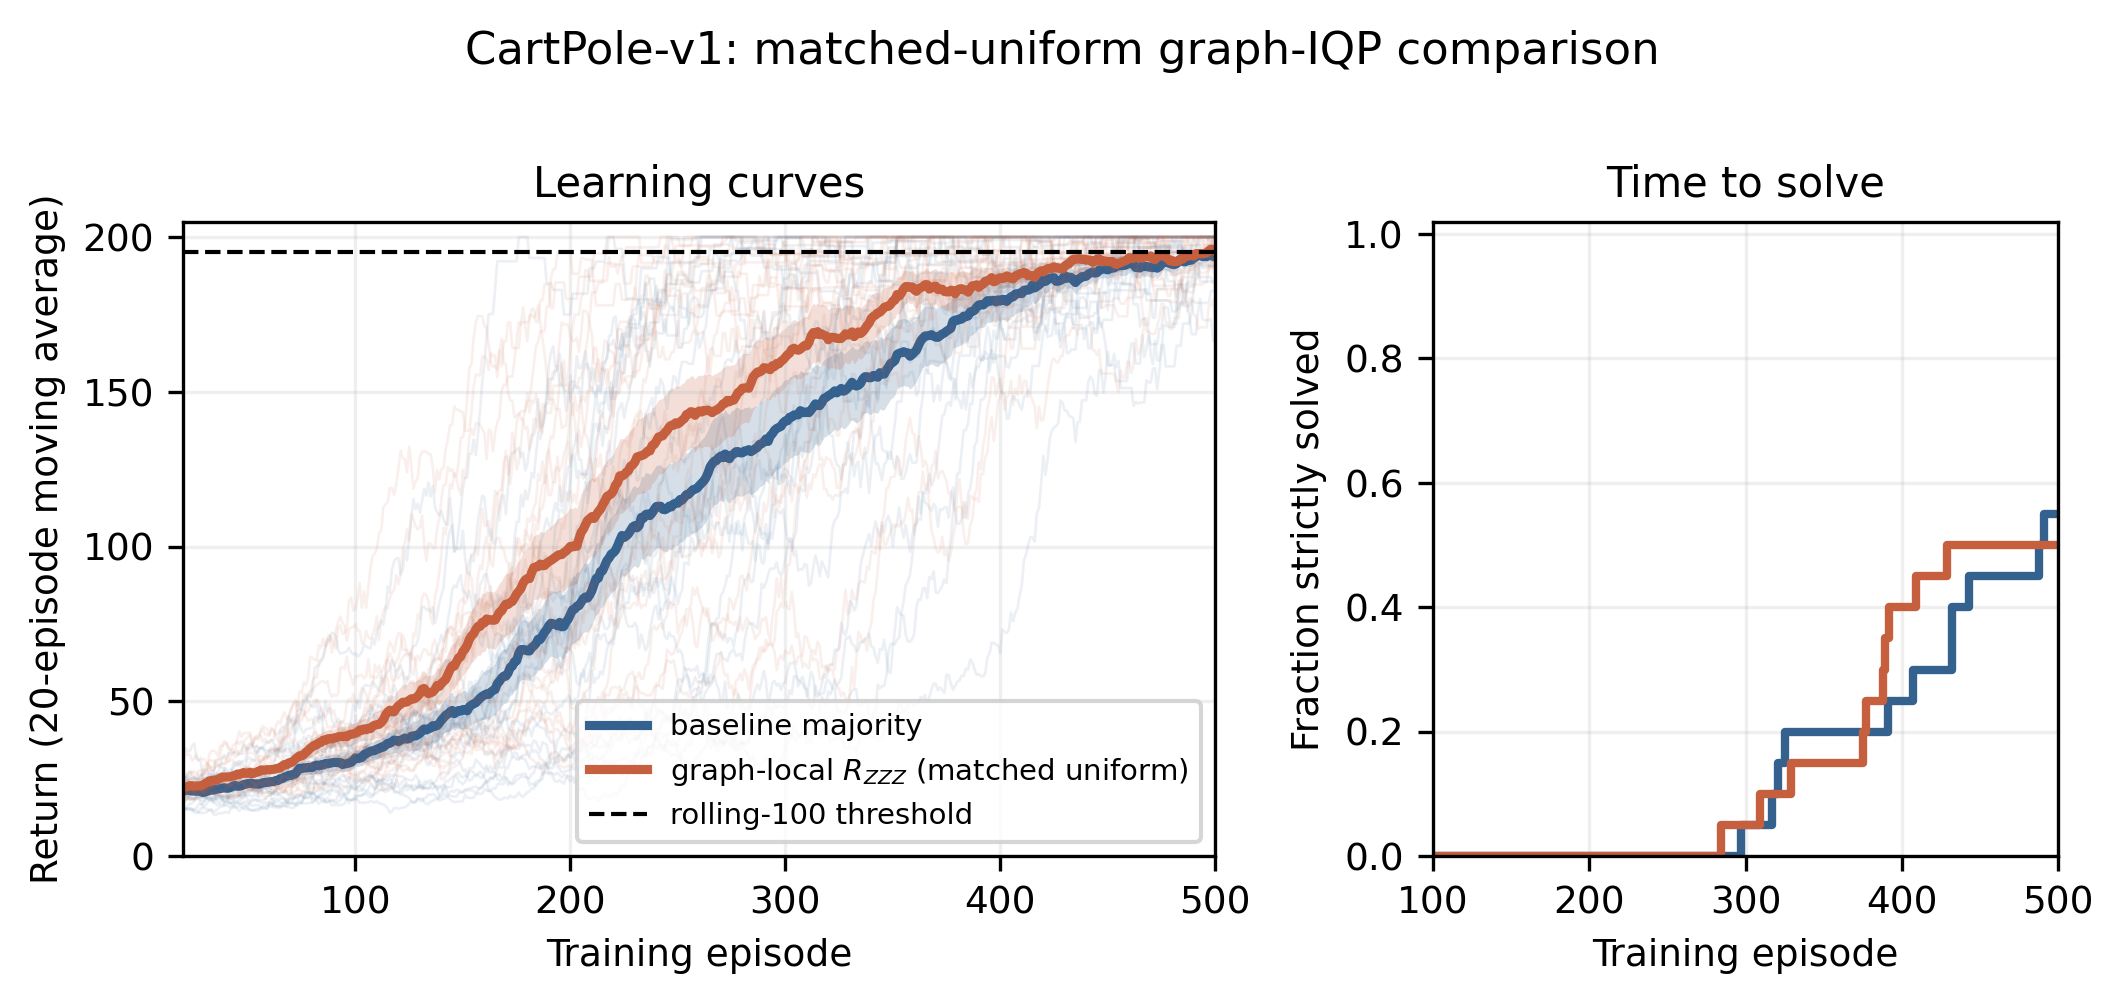

,condition,n_seeds,mean_normalized_training_auc,sem_normalized_training_auc,mean_training_final_50,sem_training_final_50,mean_heldout_evaluation,sem_heldout_evaluation,strict_solved_seed_fraction,mean_restricted_solve_episode
0,baseline majority,20,0.555073,0.030606,192.494,2.244873,193.4245,1.777721,0.55,442.65
1,graph-local RZZZ (matched uniform),20,0.616752,0.025710,194.154,1.453036,195.3990,1.078090,0.50,434.55


,contrast,n_pairs,mean_difference,bootstrap_ci95_low,bootstrap_ci95_high,one_sided_p_greater_than_zero
0,normalized_auc_candidate_minus_baseline,20,0.061678,0.003964,0.123086,0.030285
1,restricted_solve_episode_advantage,20,8.100000,-27.500000,44.450000,0.340288
2,final50_candidate_minus_baseline,20,1.660000,-2.369050,6.346025,0.253209
3,heldout_candidate_minus_baseline,20,1.974500,-1.384013,6.268500,0.204319


In [9]:
def paired_bootstrap(values, reference, seed=20261025, n_boot=50_000):
    difference = np.asarray(values, float) - np.asarray(reference, float)
    rng = np.random.default_rng(seed)
    draws = rng.choice(difference, size=(n_boot, len(difference)), replace=True).mean(axis=1)
    return float(difference.mean()), tuple(np.quantile(draws, [0.025, 0.975]))


def paired_randomization(difference, seed=20261110, n_perm=200_000):
    difference = np.asarray(difference, float)
    rng = np.random.default_rng(seed)
    observed = float(difference.mean())
    signs = rng.choice((-1.0, 1.0), size=(n_perm, len(difference)))
    null = (signs * difference).mean(axis=1)
    return float((1 + np.count_nonzero(null >= observed)) / (n_perm + 1))


def aggregate_if_complete():
    train_arrays, eval_arrays, metadata = {}, {}, {}
    for condition in ("baseline", "uniform_rzzz"):
        train_arrays[condition], eval_arrays[condition], metadata[condition] = {}, {}, {}
        for seed in SEEDS:
            stem = RUNS_DIR / f"expander_10_L1__{condition}__seed_{seed}"
            if not all(stem.with_suffix(suffix).exists()
                       for suffix in (".npz", ".pt", ".json")):
                return None
            arrays = np.load(stem.with_suffix(".npz"))
            meta = json.loads(stem.with_suffix(".json").read_text())
            train_arrays[condition][seed] = arrays["training_returns"]
            eval_arrays[condition][seed] = arrays["evaluation_returns"]
            metadata[condition][seed] = meta

    episode_rows, evaluation_rows, summary_rows = [], [], []
    display_name = {"baseline": "baseline majority",
                    "uniform_rzzz": "graph-local RZZZ (matched uniform)"}
    for condition in ("baseline", "uniform_rzzz"):
        training, evaluation = train_arrays[condition], eval_arrays[condition]
        seed_final, seed_eval, seed_auc, seed_solve = [], [], [], []
        for seed in SEEDS:
            seed_final.append(training[seed][-FINAL_WINDOW:].mean())
            seed_eval.append(evaluation[seed].mean())
            seed_auc.append(training[seed].mean() / MAX_STEPS)
            seed_solve.append(strict_solved_episode(training[seed]))
            episode_rows.extend({"condition": display_name[condition], "seed": seed,
                                 "episode": i + 1, "return": value}
                                for i, value in enumerate(training[seed]))
            evaluation_rows.extend({"condition": display_name[condition], "seed": seed,
                                    "evaluation_episode": i + 1, "return": value}
                                   for i, value in enumerate(evaluation[seed]))
        summary_rows.append({
            "condition": display_name[condition], "n_seeds": len(SEEDS),
            "mean_normalized_training_auc": float(np.mean(seed_auc)),
            "sem_normalized_training_auc": float(np.std(seed_auc, ddof=1)/math.sqrt(len(SEEDS))),
            "mean_training_final_50": float(np.mean(seed_final)),
            "sem_training_final_50": float(np.std(seed_final, ddof=1)/math.sqrt(len(SEEDS))),
            "mean_heldout_evaluation": float(np.mean(seed_eval)),
            "sem_heldout_evaluation": float(np.std(seed_eval, ddof=1)/math.sqrt(len(SEEDS))),
            "strict_solved_seed_fraction": float(np.mean(np.isfinite(seed_solve))),
            "mean_restricted_solve_episode": float(np.mean(np.where(
                np.isfinite(seed_solve), seed_solve, N_EPISODES + 1))),
        })

    episode_df = pd.DataFrame(episode_rows)
    evaluation_df = pd.DataFrame(evaluation_rows)
    summary_df = pd.DataFrame(summary_rows)
    episode_df.to_csv(RESULTS_DIR / "episode_returns.csv", index=False)
    evaluation_df.to_csv(RESULTS_DIR / "heldout_evaluation_returns.csv", index=False)
    summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)

    baseline_auc = np.asarray([train_arrays["baseline"][s].mean()/MAX_STEPS for s in SEEDS])
    candidate_auc = np.asarray([train_arrays["uniform_rzzz"][s].mean()/MAX_STEPS for s in SEEDS])
    baseline_solve = np.asarray([strict_solved_episode(train_arrays["baseline"][s]) for s in SEEDS])
    candidate_solve = np.asarray([strict_solved_episode(train_arrays["uniform_rzzz"][s]) for s in SEEDS])
    baseline_restricted = np.where(np.isfinite(baseline_solve), baseline_solve, N_EPISODES + 1)
    candidate_restricted = np.where(np.isfinite(candidate_solve), candidate_solve, N_EPISODES + 1)
    baseline_final = np.asarray([train_arrays["baseline"][s][-FINAL_WINDOW:].mean() for s in SEEDS])
    candidate_final = np.asarray([train_arrays["uniform_rzzz"][s][-FINAL_WINDOW:].mean() for s in SEEDS])
    baseline_heldout = np.asarray([eval_arrays["baseline"][s].mean() for s in SEEDS])
    candidate_heldout = np.asarray([eval_arrays["uniform_rzzz"][s].mean() for s in SEEDS])
    seed_summary_df = pd.DataFrame({
        "seed": SEEDS,
        "baseline_normalized_auc": baseline_auc,
        "candidate_normalized_auc": candidate_auc,
        "auc_candidate_minus_baseline": candidate_auc - baseline_auc,
        "baseline_strict_solve_episode": baseline_solve,
        "candidate_strict_solve_episode": candidate_solve,
        "restricted_episode_advantage_baseline_minus_candidate": baseline_restricted - candidate_restricted,
        "baseline_training_final_50": baseline_final,
        "candidate_training_final_50": candidate_final,
        "training_candidate_minus_baseline": candidate_final - baseline_final,
        "baseline_heldout_mean": baseline_heldout,
        "candidate_heldout_mean": candidate_heldout,
        "heldout_candidate_minus_baseline": candidate_heldout - baseline_heldout,
    })
    seed_summary_df.to_csv(RESULTS_DIR / "seed_level_summary.csv", index=False)
    paired_rows = []
    contrasts = (
        ("normalized_auc_candidate_minus_baseline", candidate_auc, baseline_auc, 20261110),
        ("restricted_solve_episode_advantage", baseline_restricted, candidate_restricted, 20261111),
        ("final50_candidate_minus_baseline", candidate_final, baseline_final, 20261112),
        ("heldout_candidate_minus_baseline", candidate_heldout, baseline_heldout, 20261113),
    )
    for contrast, values, reference, boot_seed in contrasts:
        delta, interval = paired_bootstrap(values, reference, seed=boot_seed)
        differences = np.asarray(values) - np.asarray(reference)
        paired_rows.append({"contrast": contrast, "n_pairs": len(SEEDS),
                            "mean_difference": delta,
                            "bootstrap_ci95_low": interval[0],
                            "bootstrap_ci95_high": interval[1],
                            "one_sided_p_greater_than_zero": paired_randomization(
                                differences, seed=boot_seed + 100)})
    paired_df = pd.DataFrame(paired_rows)
    paired_df.to_csv(RESULTS_DIR / "paired_comparisons.csv", index=False)

    baseline_key = "baseline"
    candidate_key = "uniform_rzzz"
    colors = {baseline_key: "#35618f", candidate_key: "#c65f3d"}
    display_labels = {
        baseline_key: "baseline majority",
        candidate_key: r"graph-local $R_{ZZZ}$ (matched uniform)",
    }
    fig, axes = plt.subplots(1, 2, figsize=(7.15, 3.25), dpi=300,
                             gridspec_kw={"width_ratios": [1.65, 1.0]})
    ax = axes[0]
    for condition in (baseline_key, candidate_key):
        arrays = train_arrays[condition]
        curves = np.stack([np.convolve(arrays[s], np.ones(MOVING_WINDOW)/MOVING_WINDOW,
                                       mode="valid") for s in SEEDS])
        x = np.arange(MOVING_WINDOW, N_EPISODES + 1)
        for curve in curves:
            ax.plot(x, curve, color=colors[condition], alpha=0.09, linewidth=0.65)
        mean = curves.mean(axis=0)
        sem = curves.std(axis=0, ddof=1) / math.sqrt(len(SEEDS))
        ax.plot(x, mean, color=colors[condition], linewidth=2.2,
                label=display_labels[condition])
        ax.fill_between(x, np.clip(mean-sem, 0, 200), np.clip(mean+sem, 0, 200),
                        color=colors[condition], alpha=0.20, linewidth=0)
    ax.axhline(195, color="black", linestyle="--", linewidth=1.0,
               label="rolling-100 threshold")
    ax.set(xlabel="Training episode", ylabel="Return (20-episode moving average)",
           xlim=(MOVING_WINDOW, N_EPISODES), ylim=(0, 205),
           title="Learning curves")
    ax.grid(alpha=0.2); ax.legend(loc="lower right", fontsize=7)
    ax = axes[1]
    for condition in (baseline_key, candidate_key):
        solve = np.asarray([strict_solved_episode(train_arrays[condition][s]) for s in SEEDS])
        x = np.arange(100, N_EPISODES + 1)
        fraction = np.asarray([np.mean(np.isfinite(solve) & (solve <= episode)) for episode in x])
        ax.step(x, fraction, where="post", color=colors[condition], linewidth=2.0,
                label=display_labels[condition])
    ax.set(xlabel="Training episode", ylabel="Fraction strictly solved",
           xlim=(100, N_EPISODES), ylim=(0, 1.02), title="Time to solve")
    ax.grid(alpha=0.2)
    fig.suptitle("CartPole-v1: matched-uniform graph-IQP comparison", y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "cartpole_10q_graph_local_rzzz_uniform_comparison.pdf",
                bbox_inches="tight")
    fig.savefig(FIGURES_DIR / "cartpole_10q_graph_local_rzzz_uniform_comparison.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    display(summary_df)
    display(paired_df)
    return summary_df, paired_df


aggregated = aggregate_if_complete()
if aggregated is None:
    print("No complete 20-seed matched matrix yet; aggregation correctly deferred.")

## Durable metadata and manifest

The final cell records the locked graph-local triple set, matched seeds,
uniform initialization audit, baseline provenance, software
versions, run-level costs, and checksums for every durable result.

In [10]:
software = {
    "python": sys.version, "platform": platform.platform(),
    "git_branch": CURRENT_BRANCH, "git_commit": CURRENT_COMMIT,
    "packages": {
        "qasp": getattr(qasp, "__version__", "0.1.0"),
        "pennylane": qml.__version__, "torch": torch.__version__,
        "gymnasium": gym.__version__, "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
        "joblib": joblib.__version__,
    },
}
completed = aggregated is not None
preflight = {
    "status": "complete" if completed else (
        "production_incomplete" if RUN_PRODUCTION else "configured_not_started"),
    "production_executed": bool(completed),
    "rzzz_gate_count": len(SELECTED_TRIPLES),
    "selected_triples": [list(t) for t in SELECTED_TRIPLES],
    "graph": {"master_seed": 31415, "accepted_networkx_seed": EXPECTED_GRAPH_SEED,
              "spectral_gap": graph_gap, "edges": [list(e) for e in EXPANDER_EDGES]},
    "measurement_wires": list(MEASUREMENT_WIRES),
    "coupled_unmeasured_wires": [9],
    "seeds": list(SEEDS), "training_episodes": N_EPISODES,
    "evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "environment": "CartPole-v1/200", "training": TRAINING,
    "primary_endpoint": "normalized training-return AUC over 500 episodes",
    "secondary_speed_endpoint": (
        "first strict rolling-100 mean return >=195; unsolved restricted to episode 501"
    ),
    "initialization": {
        "baseline": "original QASP uniform initialization",
        "candidate": (
            "same bitwise shared QASP initialization plus independent "
            "QASP uniform[0,2pi) RZZZ angles"
        ),
        "extra_parameter_master_seed": EXTRA_PARAMETER_MASTER_SEED,
    },
    "learning_rates": {"shared": BASE_LR, "rzzz_residual": RZZZ_LR},
    "baseline_provenance": {
        "protocol_directory": str(BASELINE_DIR),
        "baseline_run_directory": str(SOURCE_BASELINE_RUNS),
        "pairing_uses": "verified baseline checkpoints plus new candidate runs on the same seeds",
        "baseline_trajectories_reused": True,
    },
    "preflight_gate_audit": preflight_rows,
    "software": software,
}
(RESULTS_DIR / "preflight_metadata.json").write_text(
    json.dumps(preflight, indent=2, allow_nan=True)
)

experiment_config = {
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "trainer_side_step_cap": MAX_STEPS,
    "training_episodes": N_EPISODES,
    "heldout_evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "seeds": list(SEEDS), "training": TRAINING,
    "n_qubits": N_QUBITS, "n_layers": N_LAYERS,
    "graph_master_seed": 31415,
    "accepted_networkx_seed": EXPECTED_GRAPH_SEED,
    "spectral_gap": graph_gap,
    "edges": [list(edge) for edge in EXPANDER_EDGES],
    "measurement_wires": list(MEASUREMENT_WIRES),
    "coupled_unmeasured_wires": [9],
    "decoder": "deterministic majority on nine measured wires",
    "rzzz_gate_count": len(SELECTED_TRIPLES),
    "selected_triples": [list(t) for t in SELECTED_TRIPLES],
    "triple_selection": (
        "one length-two path per graph vertex; all 15 edges covered; "
        "each qubit occurs in exactly three triples; fixed before candidate evaluation"
    ),
    "rzzz_initialization": "QASP uniform[0,2pi) using a separate reproducible stream",
    "extra_parameter_master_seed": EXTRA_PARAMETER_MASTER_SEED,
    "base_learning_rate": BASE_LR,
    "rzzz_learning_rate": RZZZ_LR,
    "shared_parameter_count": 65,
    "augmented_parameter_count": 75,
    "baseline_protocol_source": str(BASELINE_CONFIG_PATH),
    "baseline_run_source": str(SOURCE_BASELINE_RUNS),
    "primary_endpoint": "normalized training-return AUC over 500 episodes",
    "secondary_endpoint": "restricted strict solve episode",
    "baseline_provenance_note": (
        "Baseline trajectories are copied from the completed twenty-seed study. "
        "The candidate uses identical shared tensors and separately sampled "
        "full-period uniform RZZZ angles."
    ),
}
(RESULTS_DIR / "experiment_config.json").write_text(
    json.dumps(experiment_config, indent=2)
)
(RESULTS_DIR / "software_metadata.json").write_text(
    json.dumps(software, indent=2)
)

run_records = []
for path in sorted(RUNS_DIR.glob("*.json")):
    record = json.loads(path.read_text())
    if record.get("condition") in {"baseline", "uniform_rzzz"}:
        run_records.append(record)
run_metadata_df = (pd.DataFrame(run_records).sort_values(["seed", "condition"])
                   if run_records else pd.DataFrame())
run_metadata_df.to_csv(RESULTS_DIR / "run_metadata.csv", index=False)

audit_rows = []
if not run_metadata_df.empty:
    by_seed_condition = run_metadata_df.set_index(["seed", "condition"])
    for seed in SEEDS:
        if ((seed, "baseline") not in by_seed_condition.index or
                (seed, "uniform_rzzz") not in by_seed_condition.index):
            continue
        base_row = by_seed_condition.loc[(seed, "baseline")]
        candidate_row = by_seed_condition.loc[(seed, "uniform_rzzz")]
        audit_rows.append({
            "seed": int(seed),
            "shared_tensors_bitwise_identical": (
                base_row.initial_shared_parameter_sha256 ==
                candidate_row.initial_shared_parameter_sha256
            ),
            "baseline_shared_parameter_sha256": base_row.initial_shared_parameter_sha256,
            "candidate_shared_parameter_sha256": candidate_row.initial_shared_parameter_sha256,
            "candidate_rzzz_uniform_parameter_sha256": candidate_row.initial_rzzz_parameter_sha256,
            "candidate_n_rzzz_gates": int(candidate_row.n_rzzz_gates),
        })
initialization_audit_df = pd.DataFrame(audit_rows)
initialization_audit_df.to_csv(RESULTS_DIR / "initialization_audit.csv", index=False)
if completed:
    assert len(run_metadata_df) == 2 * len(SEEDS)
    assert len(initialization_audit_df) == len(SEEDS)
    assert initialization_audit_df.shared_tensors_bitwise_identical.all()

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

manifest_files = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append({
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path),
        })
manifest = {
    "completed": bool(completed),
    "n_expected_runs": 2 * len(SEEDS),
    "n_completed_runs": len(run_metadata_df),
    "training_rows": (
        int(len(pd.read_csv(RESULTS_DIR / "episode_returns.csv")))
        if (RESULTS_DIR / "episode_returns.csv").exists() else 0
    ),
    "evaluation_rows": (
        int(len(pd.read_csv(RESULTS_DIR / "heldout_evaluation_returns.csv")))
        if (RESULTS_DIR / "heldout_evaluation_returns.csv").exists() else 0
    ),
    "all_cells_executed_from_clean_kernel": True,
    "total_training_seconds": (
        float(run_metadata_df.training_seconds.sum()) if not run_metadata_df.empty else 0.0
    ),
    "total_evaluation_seconds": (
        float(run_metadata_df.evaluation_seconds.sum()) if not run_metadata_df.empty else 0.0
    ),
    "total_training_circuit_calls": (
        int(run_metadata_df.training_forward_circuit_calls.sum())
        if not run_metadata_df.empty else 0
    ),
    "total_evaluation_circuit_calls": (
        int(run_metadata_df.evaluation_forward_circuit_calls.sum())
        if not run_metadata_df.empty else 0
    ),
    "files": manifest_files,
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Saved reproducibility metadata and manifest in", RESULTS_DIR)
print("Notebook production status:", preflight["status"])
print("Completed matched runs:", len(run_metadata_df), "/", 2 * len(SEEDS))

Saved reproducibility metadata and manifest in ./tests/results/cartpole_10q_graph_local_rzzz_uniform_ablation
Notebook production status: complete
Completed matched runs: 40 / 40
